# Jones pupils: polarization of the projection lens

A scalar pupil describes a projection lens by an amplitude (apodization)
and a phase (wavefront, Zernikes). At high NA the lens also changes the
**polarization** of the light: coatings and the Fresnel transmission of
every surface treat s and p differently, and the glass can be
birefringent (stress, or the intrinsic birefringence of CaF$_2$). The full
description is the **Jones pupil**: a $2\times 2$ complex matrix
$J(P_x, P_y)$ at every pupil point that maps the Jones vector of a ray
entering the lens to the one leaving it.

Eight real functions over the pupil are hard to read and hard to specify.
The literature uses these representations:

| representation | idea | reference |
|---|---|---|
| Jones–Zernike | each element $J_{jk}$ expanded into Zernikes | e.g. Totzeck et al. 2005 |
| Pauli–Zernike | $J = \sum_k a_k\sigma_k$, each $a_k$ expanded into Zernikes; $a_0$ is the scalar pupil, $a_1, a_2$ linear and $a_3$ circular retardance (imaginary parts) and diattenuation (real parts) | McIntyre, Kye, Levinson, Neureuther, JM3 5(3) 033001 (2006) |
| physical decomposition | polar decomposition $J = \sqrt{T}e^{i\Phi}\,U H$: transmission, phase, retarder $U$, diattenuator $H$ | Totzeck, Gräupner, Heil et al., JM3 4(3) 031108 (2005); Geh et al. |
| orientation Zernike polynomials (OZP) | retardance and diattenuation are *orientation fields* (an axis, defined modulo 180°), expanded into vector polynomials with Zernike radial parts | Ruoff, Totzeck, JM3 8(3) 031404 (2009); US patent 8,126,669 |

McIntyre et al. found the Pauli form the most useful for lithographers: its
coefficients separate the physical effects and are linear in small
perturbations. The OZPs go one step further for retardance and
diattenuation: like scalar Zernikes they sort the orientation fields by
symmetry, so a rotationally symmetric radial retardance (typical for
coatings and mount stress) is a single term, and they are used to specify
and tolerance lenses through linear and quadratic sensitivities of CD and
placement.

`pyoptics.litho.jones_pupil` implements these bases in a modular way:

- `pauli_matrix`, `pauli_coefficients`: the Pauli algebra,
- `orientation_zernike(±j, P_x, P_y)`: OZPs as complex orientators
  $o_1 + i o_2 = |o|e^{2i\psi}$,
- `PauliZernikePupil`, `PhysicalJonesPupil` (retardance and diattenuation in
  OZPs, circular parts in Zernikes), both with `.fit()` to sampled Jones
  matrices,
- `compose`/`decompose`: the polar decomposition.

Any callable `J(P_x, P_y)` can be passed as `Projector(jones_pupil=...)`.
It acts on the Jones vector of every diffraction order before the aplanatic
rotation into image space, in Abbe and in Hopkins (`hopkins.TCC`) imaging.
`lens.lens_jones_pupil()` computes the Jones pupil of a ray traced lens by
polarization ray tracing (Chipman's $3\times 3$ matrices, Fresnel
coefficients of each surface, optional thin film coatings).

**About the lens.** The ray traced example is the dioptric ArF water
immersion lens of Zeiss patent US 7,187,503 B2 (`raytrace.zeiss_arfi_lens()`:
193.368 nm, NA 1.35, 8x, all fused silica, 11 aspheres, 1 mm of water in front
of the wafer). Its rays reach the large angles of a hyper-NA lens, up to 65°
in the water and on the last surfaces, which is where polarization effects
come from. Production ArFi lenses are catadioptric and have optimized
multilayer coatings; the quarter wave coatings and the CaF$_2$ elements here
are models of the mechanisms. Section 6 works with OZP coefficients chosen
by hand on a generic ArF immersion `Projector`.

Contents:

1. Orientation Zernike polynomials.
2. Polarization ray trace of the ArFi lens: uncoated and with an
   antireflection coating.
3. The same Jones pupil in the Pauli–Zernike and OZP bases.
4. Where retardance comes from: coatings at large angles, the intrinsic
   birefringence of CaF$_2$ and its compensation by clocking, stress.
5. Imaging with the lens Jones pupils at NA 1.35, with the coated lens and
   its CaF$_2$ variants.
6. OZP sensitivities of CD at NA 1.35: what a lens specification needs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, lens
from pyoptics.litho import jones_pupil as jp
from pyoptics.litho.plot import plot_orientation
from pyoptics.raytrace import SIO2_ARF, WATER_ARF, zeiss_arfi_lens

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

## 1. Orientation Zernike polynomials

An orientation $\psi$ (the fast axis of a retarder, the axis of best
transmission of a diattenuator) is defined modulo 180°. It is described by
the **orientator** $o = |o|\,e^{2i\psi}$, a 2-vector that turns twice as fast
as the axis. OZPs are a complete basis of orientator fields: the Zernike
radial polynomials $R_n^{|m|}(\rho)$ times $e^{\pm i m\phi}$, real and
imaginary (two OZPs per Zernike). Here they are labelled $\pm j$ with the
Fringe index $j$ such that the first component of OZ $+j$ is $Z_j$, as in
the patent; OZ $-j$ flips the sign of the second component. Examples:

- OZ $\pm 1$: constant orientation along x/y and along ±45°,
- OZ $\pm 2$, $\pm 3$: tilt-like, linear in $\rho$,
- OZ $+5 = \rho^2 e^{2i\phi}$: **radial** orientation (tangential for a
  negative coefficient), OZ $-6$: the same rotated by 45°, a spiral; both
  are rotationally symmetric,
- OZ $+4$, $+9$: x/y orientation with defocus- and spherical-like radial
  dependence.

The plots show the magnitude (color) and the orientation (ticks).

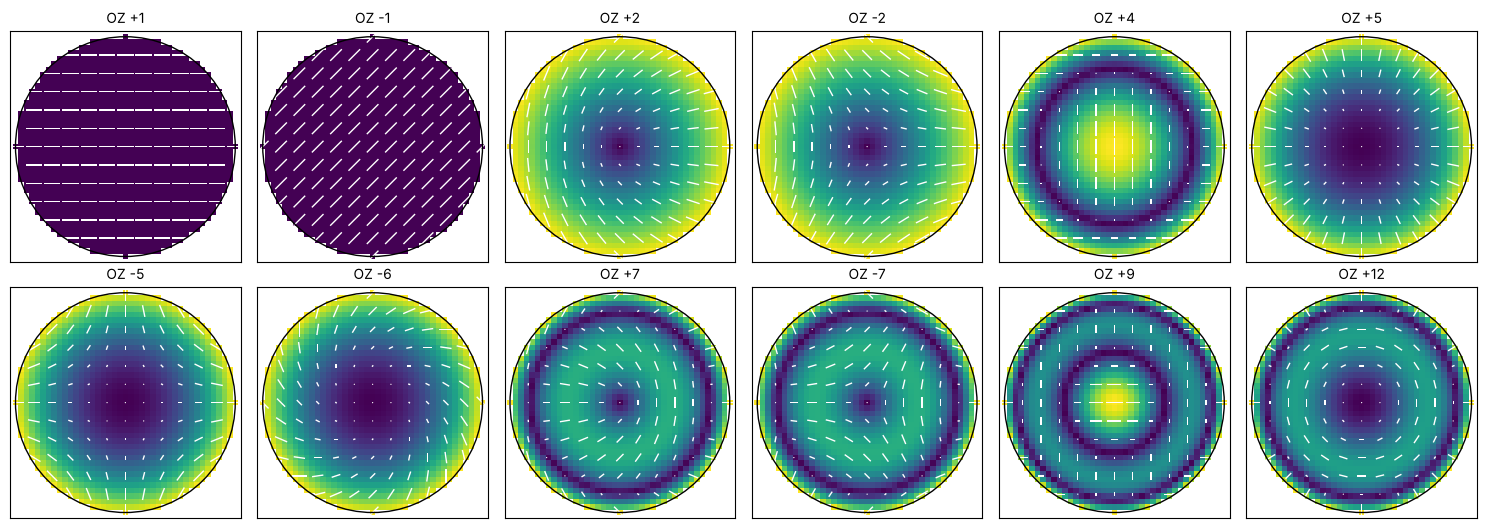

In [2]:
terms = [1, -1, 2, -2, 4, 5, -5, -6, 7, -7, 9, 12]
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for ax, oz in zip(axes.ravel(), terms):
    plot_orientation(lambda P_x, P_y: jp.orientation_zernike(oz, P_x, P_y), ax=ax,
                     title="OZ {:+d}".format(oz), colorbar=False)
plt.tight_layout()

Under a rotation of the lens by $\alpha$ an orientator rotates by $2\alpha$,
so the term $e^{im\phi}$ picks up $e^{i(2-m)\alpha}$. Only $m = 2$
($+5$, $-6$, $+12$, $-13$, ...) is rotationally symmetric. This is why a
rotationally symmetric lens has a Jones pupil of OZ $+5, +12, +21, \dots$
(radial/tangential) and $-6, -13, \dots$ (spiral) only, just as its
wavefront has only $Z_4, Z_9, \dots$.

## 2. Polarization ray trace of the ArFi lens

`lens_jones_pupil()` traces rays through the pupil of the water immersion
lens (NA 1.35, 43 surfaces, see the introduction). At every surface it builds Chipman's
polarization ray tracing matrix

$$P = t_s\,\hat s\hat s^T + t_p\,\hat p'\hat p^T + \hat k'\hat k^T,$$

with the Fresnel amplitude transmissions $t_s$, $t_p$ (scaled such that
$|P\vec E|^2$ is the transmitted power) and multiplies them. The Jones pupil
is the product between the aplanatic bases of the object and the image
space ray (the identity for an ideal lens). It is normalized to the chief
ray, which leaves the dose unchanged.

Two cases: uncoated (every surface reflects about 5 % at normal incidence),
and every glass–helium surface with an ideal single-layer quarter-wave
antireflection coating ($n_c = \sqrt{n_\mathrm{glass}}$). The last surface,
glass to water, reflects only 0.3 % and stays bare.

In [3]:
system = zeiss_arfi_lens()
n_glass = SIO2_ARF
layers = lens.quarter_wave_coating(n_glass, system.wavelength)
last = len(system.surfaces) - 1  # glass to water

def coating(i, n):
    return None if i == last else layers

print("fused silica n = {:.4f}, coating n = {:.4f}, thickness {:.1f} nm".format(
    n_glass, layers[0][0], layers[0][1]*1e6))

uncoated = lens.lens_jones_pupil(system, N=41)
coated = lens.lens_jones_pupil(system, N=41, coating=coating)
for name, r in (("uncoated", uncoated), ("coated", coated)):
    print("{:9s}: chief ray transmission {:.3f}, {} rays, NA {:.3f}".format(
        name, r.transmission, len(r.P_x), r.NA))

fused silica n = 1.5608, coating n = 1.2493, thickness 38.7 nm


uncoated : chief ray transmission 0.133, 1257 rays, NA 1.350
coated   : chief ray transmission 0.998, 1257 rays, NA 1.350


`decompose()` splits every Jones matrix into the scalar transmission $T$ and
phase $\Phi$, the linear diattenuation $d$ (orientator, magnitude
$(T_\max - T_\min)/(T_\max + T_\min)$) and the linear retardance (orientator,
in waves).

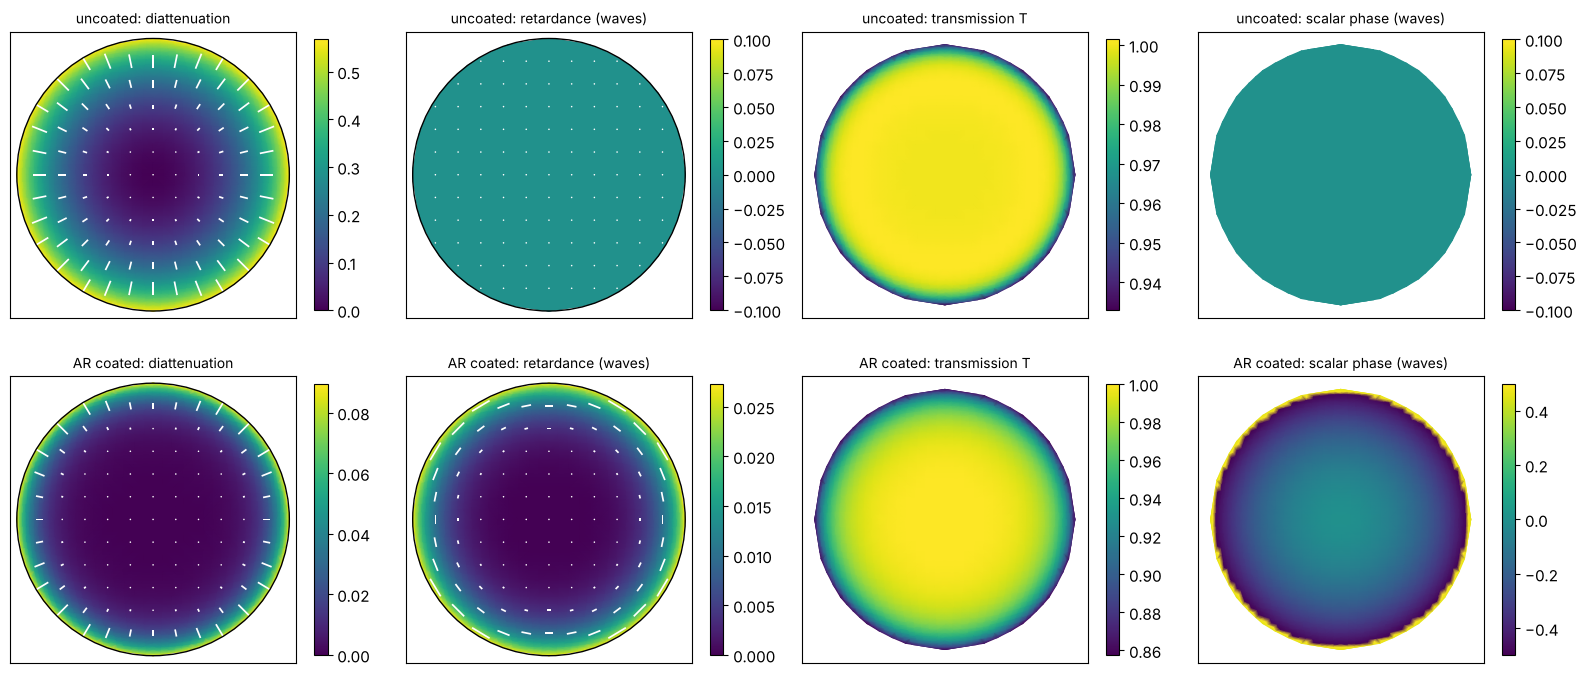

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.2))
for row, (name, r) in zip(axes, (("uncoated", uncoated), ("AR coated", coated))):
    parts = jp.decompose(r.J)
    d, g = parts["diattenuation"], parts["retardance"]
    plot_orientation((r.P_x, r.P_y, d[0] + 1j*d[1]), ax=row[0], title=name + ": diattenuation")
    plot_orientation((r.P_x, r.P_y, g[0] + 1j*g[1]), ax=row[1],
                     title=name + ": retardance (waves)")
    for ax, v, title in ((row[2], parts["transmission"], "transmission T"),
                         (row[3], parts["phase"]/(2*np.pi), "scalar phase (waves)")):
        im = ax.tripcolor(r.P_x, r.P_y, v, shading="gouraud", cmap="viridis")
        ax.set_aspect("equal"), ax.set_xticks([]), ax.set_yticks([])
        ax.set_title(name + ": " + title, fontsize=10)
        plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()

The **uncoated** lens is a pure radial diattenuator: $p$ is transmitted
better than $s$ at oblique incidence (Brewster), and 43 surfaces add up to
a strong effect at the rim of the pupil. The Fresnel coefficients are real,
so there is no retardance. The **coating** removes most of the
diattenuation but adds retardance, because the phase of the transmission of
a thin film differs for s and p at oblique incidence. It also adds a
rotationally symmetric scalar phase, a wavefront error that the lens
designer has to include in the optimization.

## 3. The Jones pupil in the Pauli–Zernike and OZP bases

`PauliZernikePupil.fit()` expands the four Pauli coefficients into
Zernikes, `PhysicalJonesPupil.fit()` the decomposition: OZPs for linear
retardance and diattenuation, Zernikes for the circular parts and for the
scalar transmission and phase (returned separately, since these belong to
the Projector's apodization and Zernikes).

In [5]:
def large(coefficients, tol=1e-4):
    return {k: round(v, 4) for k, v in coefficients.items() if abs(v) > tol}

fits = {}
for name, r in (("uncoated", uncoated), ("coated", coated)):
    physical, scalar = jp.PhysicalJonesPupil.fit(r.P_x, r.P_y, r.J, n_terms=25)
    pauli = jp.PauliZernikePupil.fit(r.P_x, r.P_y, r.J, n_terms=36)
    fits[name] = physical, scalar, pauli
    print(name)
    print("  diattenuation OZP:  ", large(physical.diattenuation))
    print("  retardance OZP:     ", large(physical.retardance))
    print("  circular retardance:", large(physical.circular_retardance))
    print("  scalar phase:       ", large(scalar["phase"]))
    print("  transmission:       ", large(scalar["transmission"]))
    print("  fit errors |J_fit - J|: physical {:.1e}, Pauli-Zernike {:.1e}".format(
        np.abs(jp.compose(*physical.fields(r.P_x, r.P_y)) - jp.scalar_free(r.J)).max(),
        np.abs(pauli(r.P_x, r.P_y) - r.J).max()))

uncoated
  diattenuation OZP:   {5: 0.4977, 12: 0.0557, 21: 0.0118}
  retardance OZP:      {}
  circular retardance: {}
  scalar phase:        {}
  transmission:        {1: 0.9944, 4: -0.0157, 9: -0.0187, 16: -0.0133, 17: 0.0002, 25: -0.0089}
  fit errors |J_fit - J|: physical 2.2e-03, Pauli-Zernike 1.8e-03
coated
  diattenuation OZP:   {5: 0.0441, 12: 0.0285, 21: 0.0128, -21: -0.0001}
  retardance OZP:      {5: -0.017, 12: -0.0079, 21: -0.0019}
  circular retardance: {}
  scalar phase:        {1: -0.1968, 4: -0.1088, 9: 0.2132, 16: 0.2555, 17: -0.0004, 25: 0.3765}
  transmission:        {1: 0.9731, 4: -0.0501, 9: -0.0342, 16: -0.0165, 17: 0.0002, 25: -0.0099}
  fit errors |J_fit - J|: physical 2.8e-03, Pauli-Zernike 7.2e-03


A handful of rotationally symmetric terms (OZ $+5$, $+12$, $+21$) describe
the polarization of the centred lens. In the Pauli basis the same
information is spread over $a_1$ and $a_2$, each with many Zernike terms:

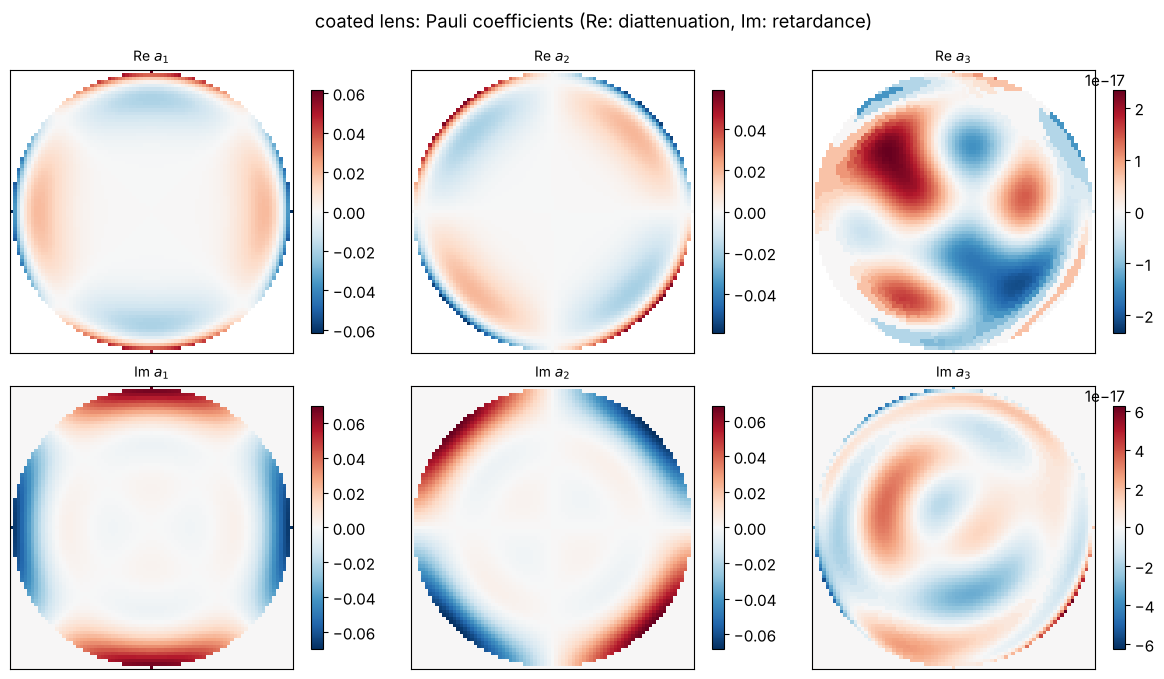

In [6]:
physical, scalar, pauli = fits["coated"]
P = np.linspace(-1, 1, 81)
PX, PY = np.meshgrid(P, P)
a = pauli.pauli(PX, PY)
a = np.where(PX**2 + PY**2 <= 1, a, np.nan)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for k in range(1, 4):
    for row, (part, f) in enumerate((("Re", np.real), ("Im", np.imag))):
        ax = axes[row, k - 1]
        v = f(a[k])
        lim = np.nanmax(np.abs(v)) or 1
        im = ax.pcolormesh(P, P, v, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
        ax.set_aspect("equal"), ax.set_xticks([]), ax.set_yticks([])
        ax.set_title("{} $a_{}$".format(part, k), fontsize=10)
        plt.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("coated lens: Pauli coefficients (Re: diattenuation, Im: retardance)")
plt.tight_layout()

For a rotationally symmetric lens, $a_1 \propto \cos 2\phi$ and
$a_2 \propto \sin 2\phi$ (astigmatism-like Zernikes $Z_5, Z_6, Z_{12},
Z_{13}, \dots$); the OZP basis collects both into one term per radial order.

### Through the field

Off axis the chief ray crosses the lens surfaces obliquely. Constant
(OZ $\pm1$) and tilt-like (OZ $\pm2$, $\pm3$) terms appear, and they grow
with the field, much like distortion and coma in the wavefront:

(<matplotlib.legend.Legend at 0x7f7473e5cec0>, None)

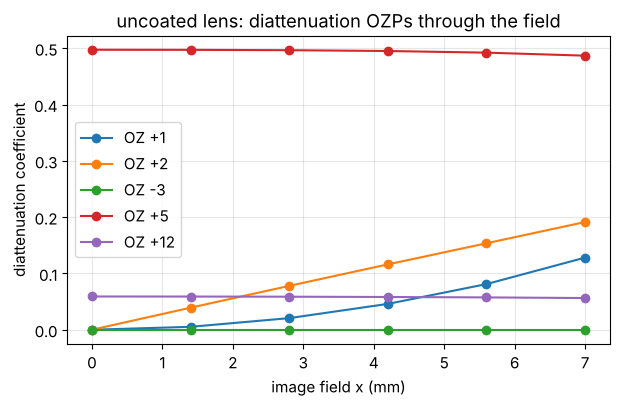

In [7]:
field_x = np.linspace(0, 7, 6)
rows = []
for x in field_x:
    r = lens.lens_jones_pupil(system, field=(x, 0.0), N=25)
    f, _ = jp.PhysicalJonesPupil.fit(r.P_x, r.P_y, r.J, n_terms=16)
    rows.append(f.diattenuation)
fig, ax = plt.subplots(figsize=(7, 4))
for oz in (1, 2, -3, 5, 12):
    ax.plot(field_x, [row[oz] for row in rows], "o-", label="OZ {:+d}".format(oz))
ax.set_xlabel("image field x (mm)"), ax.set_ylabel("diattenuation coefficient")
ax.set_title("uncoated lens: diattenuation OZPs through the field")
ax.legend(), ax.grid(alpha=0.3)

## 4. Where retardance comes from

The uncoated lens above is almost a pure diattenuator, because the Fresnel
coefficients of a bare surface are real. Retardance, the phase difference
between two polarizations, has other sources, and in practice it is the
larger problem: it converts the TE polarization that a polarized
illuminator delivers into TM, which images with less contrast at high NA
(section 6).

- **Coatings at large angles.** A thin film shifts the phase of $s$ and
  $p$ differently as soon as the incidence is oblique. The difference grows
  quickly with the angle, so the surfaces near the wafer of a hyper-NA lens,
  with angles of incidence of 50–70°, dominate.
- **Intrinsic birefringence of CaF$_2$.** ArF lenses use CaF$_2$ for the
  elements that see the highest fluence (it does not compact like fused
  silica). As a cubic crystal it is isotropic to lowest order, but at short
  wavelengths it has a small birefringence that depends on the direction of
  the ray (Burnett et al. 2001): 3.4 nm/cm at 193 nm, 11.2 nm/cm at 157 nm.
  This was a main reason why 157 nm lithography was abandoned.
- **Stress birefringence** from mounts, from the annealing of large blanks
  and from compaction of fused silica under ArF exposure. It is specified
  in nm/cm and usually appears as low order radial or tangential OZ terms;
  `PhysicalJonesPupil(retardance={5: ..., -6: ...})` models it directly.

### Coatings: retardance per surface vs. the angle of incidence

One fused silica surface at 193.368 nm ($n = 1.5608$), uncoated and with the
quarter wave coating of section 2, and the angles of incidence that occur on
the surfaces of the lens (grey):

surfaces with the largest angles (surface: deg): 34: 68, 21: 66, 11: 51, 14: 48, 40: 47, 22: 46


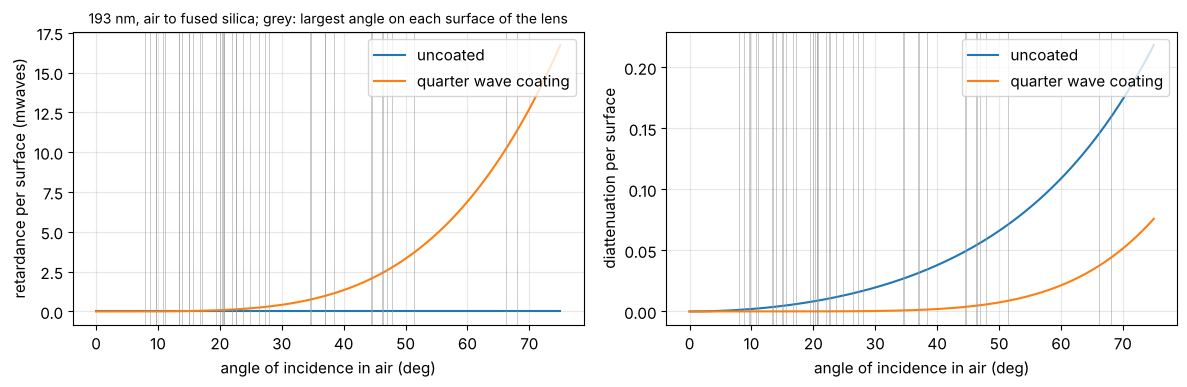

In [8]:
from pyoptics import thin_films

n_glass_arf = SIO2_ARF
wl_arf = system.wavelength_nm
layer = lens.quarter_wave_coating(n_glass_arf, wl_arf)[0]
angles = np.radians(np.linspace(0.0, 75.0, 151))

def surface_polarization(n_layer, d_layer):
    t = {pol: np.array([thin_films.r_t_coeffs(a, [n_layer], [0.0], [d_layer], 1.0, 0.0, n_glass_arf,
                                              0.0, pol, wl_arf)[1] for a in angles])
         for pol in ("s", "p")}
    T = {pol: np.array([thin_films.R_T_A_coeffs(a, [n_layer], [0.0], [d_layer], 1.0, 0.0, n_glass_arf,
                                                0.0, pol, wl_arf)[1] for a in angles])
         for pol in ("s", "p")}
    retardance = np.angle(t["p"]/t["s"])/(2*np.pi)  # waves
    return retardance, (T["p"] - T["s"])/(T["p"] + T["s"])

def max_angles_in_air(system, N=21):
    # largest angle of incidence on each surface, on the gas side (Snell), over the pupil and field
    n = system.n
    frames = system.frames()[0]
    p = np.linspace(-1, 1, N)
    PX, PY = np.meshgrid(p, p)
    inside = PX**2 + PY**2 <= 1
    worst = np.zeros(len(system.surfaces))
    for field in (0.0, system.max_field):
        b = system.trace_pupil(field, PX[inside], PY[inside])
        for i, s in enumerate(system.surfaces):
            o, R = frames[i]
            Q = (b.points[i + 1][b.valid] - o) @ R
            cos_i = np.abs(np.sum(s.normal(Q)*(b.directions[i][b.valid] @ R), axis=-1))
            worst[i] = max(worst[i], np.max(n[i]*np.sqrt(1 - cos_i**2)))
    return np.degrees(np.arcsin(np.clip(worst, 0, 1)))

aoi = max_angles_in_air(system)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (n_l, d_l), name in (((1.0, 0.0), "uncoated"), (layer, "quarter wave coating")):
    ret, dia = surface_polarization(n_l, d_l)
    axes[0].plot(np.degrees(angles), 1e3*ret, label=name)
    axes[1].plot(np.degrees(angles), dia, label=name)
axes[0].set_ylabel("retardance per surface (mwaves)"), axes[1].set_ylabel("diattenuation per surface")
for ax in axes:
    for a in aoi[1:-1]:
        ax.axvline(a, color="0.6", lw=0.6, alpha=0.6)
    ax.set_xlabel("angle of incidence in air (deg)"), ax.grid(alpha=0.3), ax.legend()
axes[0].set_title("193 nm, air to fused silica; grey: largest angle on each surface of the lens", fontsize=10)
plt.tight_layout()
gas = aoi[:-1]  # the glass to water surface has no gas side
print("surfaces with the largest angles (surface: deg):",
      ", ".join("{}: {:.0f}".format(system.surfaces[i].label, gas[i]) for i in np.argsort(gas)[::-1][:6]))

The uncoated surface has no retardance at all; the coating has some
that grows steeply with the angle, and several surfaces of this lens see
angles far beyond those of a dry lens. This is
why ArFi lens coatings are designed for low retardance over the angles of
each surface, and why a simple quarter wave coating, as used here, is only
a teaching model.

### Intrinsic birefringence of CaF$_2$

`lens.CubicCrystal(delta_n, axis, clocking)` adds this birefringence to the
paths inside chosen elements of the ray trace. To lowest order the change
of the index for a ray along $\hat k$ (crystal axes) is set by the tensor
$\mathrm{diag}(k_x^2, k_y^2, k_z^2)$ on the transverse plane: it vanishes
along the $\langle 100\rangle$ and $\langle 111\rangle$ axes and is largest
along $\langle 110\rangle$, where it equals $\Delta n$. An element cut with
[111] along the lens axis therefore has no retardance on axis, and a
retardance with threefold symmetry for oblique rays; [100] elements have
fourfold symmetry.

Production ArFi lenses use CaF$_2$ for the last elements, where the
fluence is highest. We make the last three elements of the lens "CaF$_2$"
(the media behind surfaces 39, 41 and 43 of the patent, system indices 38,
40 and 42, 61, 54 and 60 mm thick) by giving them the birefringence of
CaF$_2$, keeping the fused silica index so that the design stays
corrected. The surfaces carry the quarter wave coating.

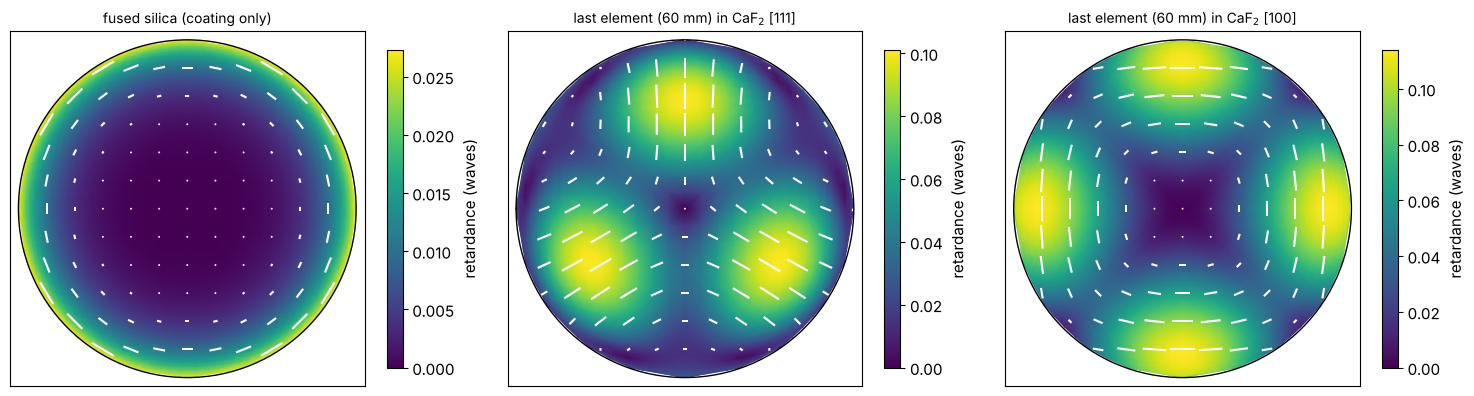

In [9]:
DN_ARF = -3.4e-7  # CaF2 at 193 nm, Burnett et al. (2001)
dn = DN_ARF
caf2 = (38, 40, 42)

def crystal_pupil(axes_clockings, N=33):
    media = {i: lens.CubicCrystal(dn, a, np.radians(c)) for i, (a, c) in zip(caf2, axes_clockings)}
    return lens.lens_jones_pupil(system, N=N, coating=coating, birefringent=media)

def retardance_orientator(r):
    g = jp.decompose(r.J)["retardance"]
    return g[0] + 1j*g[1]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
r_si = coated
plot_orientation((r_si.P_x, r_si.P_y, retardance_orientator(r_si)), ax=axes[0],
                 title="fused silica (coating only)", label="retardance (waves)")
for ax, axis in zip(axes[1:], ("111", "100")):
    media = {42: lens.CubicCrystal(dn, axis)}
    r = lens.lens_jones_pupil(system, N=33, coating=coating, birefringent=media)
    plot_orientation((r.P_x, r.P_y, retardance_orientator(r)), ax=ax,
                     title="last element (60 mm) in CaF$_2$ [{}]".format(axis), label="retardance (waves)")
plt.tight_layout()

A single thick [111] element already brings a retardance of about a tenth
of a wave at the rim, much more than the coatings, with a threefold
pattern (OZ $\pm3$, $\pm8$, ...: the terms that pick up $e^{3i\alpha}$
under a rotation) on top of a rotationally symmetric part (OZ $+5$). The
[100] element has a fourfold pattern (OZ $-5$, ...) and a rotationally
symmetric part of the *opposite* sign.

### Compensation by clocking

Rotating an element about the lens axis (clocking) rotates its pattern.
Two [111] elements clocked by 60° have opposite threefold parts, which
cancel as far as their paths are similar, and their rotationally symmetric
parts add up; a [100] element can then compensate the rotationally symmetric
part. This is the compensation that Burnett and coworkers proposed for the
CaF$_2$ elements of ArF and F$_2$ lenses. Here we try all combinations of [111] at 0° or
60° and [100] at 0° or 45° for the three elements and rank them by the RMS
retardance over the pupil:

RMS / max retardance (waves at 193 nm)   elements 39, 41, 43 (axis, clocking)
  0.0275   0.0552   [111] 60°, [100]  0°, [111]  0°
  0.0275   0.0552   [111]  0°, [100]  0°, [111] 60°
  0.0279   0.0597   [111]  0°, [100] 45°, [111] 60°
  0.0279   0.0597   [111] 60°, [100] 45°, [111]  0°
  0.1095   0.1683   [100]  0°, [100] 45°, [100] 45°
  0.1101   0.1761   [100]  0°, [100]  0°, [100]  0°
  0.1121   0.1760   [100] 45°, [100] 45°, [100] 45°
all [111], not clocked: RMS 0.1077
fused silica only: RMS 0.0143


all [111], not clocked retardance OZP: {3: -0.1316, 5: 0.0738, 8: 0.1052, 12: -0.0617, 21: -0.0043}
best clocking retardance OZP: {3: -0.0197, 5: 0.004, -5: -0.0175, 8: 0.0372, 12: -0.0266, -12: 0.0062, 15: -0.0068}


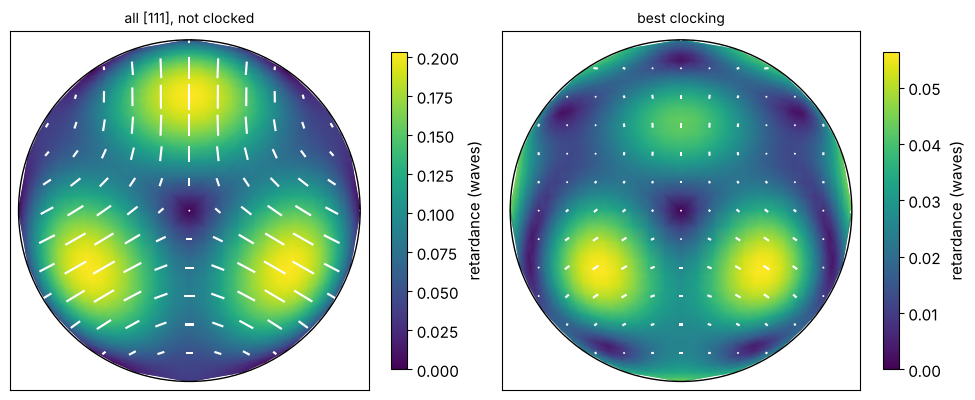

In [10]:
import itertools

options = [("111", 0), ("111", 60), ("100", 0), ("100", 45)]
ranking = []
for combo in itertools.product(options, repeat=3):
    g = retardance_orientator(crystal_pupil(combo, N=21))
    ranking.append((np.sqrt(np.mean(np.abs(g)**2)), np.abs(g).max(), combo))
ranking.sort(key=lambda row: row[0])
print("RMS / max retardance (waves at 193 nm)   elements 39, 41, 43 (axis, clocking)")
for rms, peak, combo in ranking[:4] + ranking[-3:]:
    print("{:8.4f} {:8.4f}   {}".format(rms, peak, ", ".join("[{}] {:>2d}°".format(a, c) for a, c in combo)))
print("all [111], not clocked: RMS {:.4f}".format(next(rms for rms, _, c in ranking if c == (("111", 0),)*3)))
print("fused silica only: RMS {:.4f}".format(np.sqrt(np.mean(np.abs(retardance_orientator(coated))**2))))

unclocked, best = (("111", 0),)*3, ranking[0][2]
crystal = {"all [111], not clocked": crystal_pupil(unclocked), "best clocking": crystal_pupil(best)}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
vmax = max(np.abs(retardance_orientator(r)).max() for r in crystal.values())
for ax, (name, r) in zip(axes, crystal.items()):
    plot_orientation((r.P_x, r.P_y, retardance_orientator(r)), ax=ax, title=name, scale=vmax,
                     label="retardance (waves)")
plt.tight_layout()
for name, r in crystal.items():
    f, _ = jp.PhysicalJonesPupil.fit(r.P_x, r.P_y, r.J, n_terms=25)
    print(name, "retardance OZP:", large(f.retardance, 3e-3))

Clocking reduces the RMS retardance about fourfold (0.108 to 0.028 waves). What is left is mostly
the part that the three elements of different thicknesses and ray angles
cannot cancel; a real design chooses thicknesses and crystal axes together
with the clocking, and adds compensating coatings or stress plates.

## 5. Imaging with the lens Jones pupils

`Projector(jones_pupil=...)` takes any of the fitted pupils. For the
ArFi lens (NA 1.35, water) we compare the CD of dense lines through
pitch with an annular source, polarized along x (TM for these vertical
lines), along y (TE) and unpolarized. For the coated lens we use the
polarization part only (`PhysicalJonesPupil`, without its scalar phase) and
the full Jones pupil, which includes the coating's wavefront.

CD change vs. no Jones pupil (nm), pitches [90.0, 120.0, 180.0, 300.0]
  x            uncoated               [  nan -6.11 -0.75 -3.79]
  x            coated (polarization)  [  nan -0.41 -0.13 -0.36]
  x            coated (full)          [   nan  -6.91 -18.49 -25.15]
  y            uncoated               [ 8.15  1.37 -0.18  0.94]
  y            coated (polarization)  [0.59 0.09 0.   0.13]
  y            coated (full)          [  8.45  -2.16 -12.19 -15.11]
  unpolarized  uncoated               [ 7.57 -0.34 -0.2  -0.66]
  unpolarized  coated (polarization)  [ 0.27 -0.02 -0.04 -0.06]
  unpolarized  coated (full)          [ 19.72  -3.38 -15.01 -19.38]


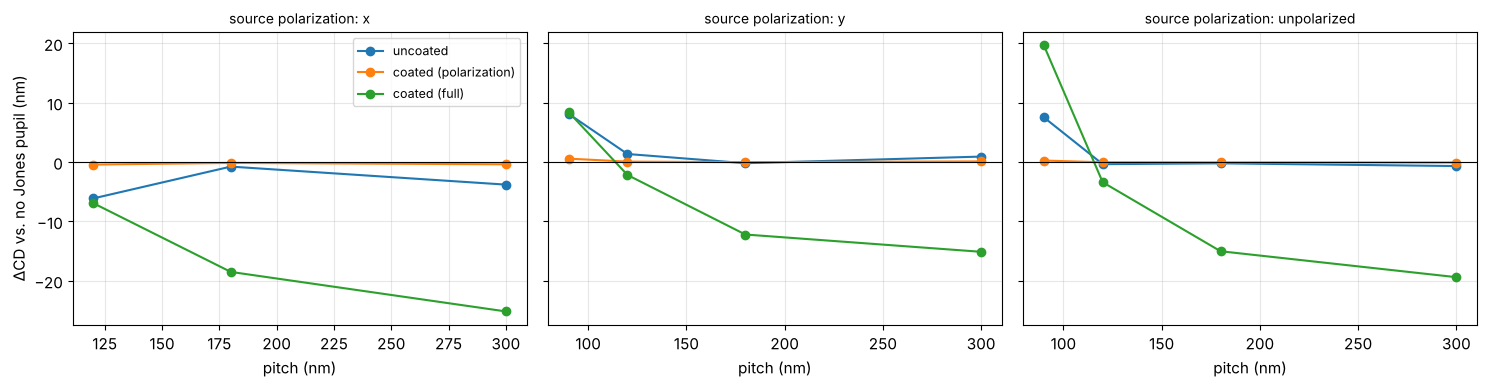

In [11]:
uncoated_pupil = fits["uncoated"][2]  # Pauli-Zernike: the full Jones pupil
coated_full = fits["coated"][2]
coated_polarization = fits["coated"][0]  # retardance and diattenuation only
projector = Projector(uncoated.NA, system.wavelength_nm, n=WATER_ARF, magnification=8.0)
pupils = {"no Jones pupil": None, "uncoated": uncoated_pupil,
          "coated (polarization)": coated_polarization, "coated (full)": coated_full}
pitches = [90.0, 120.0, 180.0, 300.0]
sources = {pol: Illumination.annular(0.85, 0.55, n_samples=21, polarization=pol)
           for pol in ("x", "y", "unpolarized")}

cd = {}
for pol, source in sources.items():
    for name, pupil in pupils.items():
        cd[pol, name] = [LithoSimulation(MaskLayout.lines_spaces(p, p/2), ThinMask.binary(), source,
                                         projector.with_(jones_pupil=pupil)).cd(0.3)
                         for p in pitches]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, pol in zip(axes, sources):
    for name in list(pupils)[1:]:
        ax.plot(pitches, np.subtract(cd[pol, name], cd[pol, "no Jones pupil"]), "o-", label=name)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title("source polarization: " + pol, fontsize=10)
    ax.set_xlabel("pitch (nm)"), ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$\Delta$CD vs. no Jones pupil (nm)")
axes[0].legend(fontsize=9)
plt.tight_layout()
print("CD change vs. no Jones pupil (nm), pitches", pitches)
for pol in sources:
    for name in list(pupils)[1:]:
        print("  {:12s} {:22s}".format(pol, name), np.round(np.subtract(cd[pol, name], cd[pol, "no Jones pupil"]), 2))

The radial diattenuation of the uncoated lens favours the TM ($p$) part of
the orders at the rim of the pupil. At NA 1.35 the first orders of the
densest pitch pass close to the rim, so it changes the balance between the
orders and with it the CD: by 8 nm at a pitch of 90 nm with y (TE)
polarization, and by 6 nm at 120 nm with x (TM) polarization (at 90 nm the
TM image is too weak to print). With unpolarized light the TE part
dominates the image of the densest pitch, and the shift stays. The
polarization part of the coated lens moves the CD by less than 1 nm. Its
scalar phase, however, is a rotationally symmetric wavefront of several
tenths of a wave ($Z_9$, $Z_{16}$, $Z_{25}$: the quarter wave coatings at
the steep surfaces near the wafer) and changes the CD of the larger pitches
by up to 25 nm: for a real lens it is part of the wavefront budget and is
designed out together with the coatings.

### The CaF$_2$ variants

The case for the retardance of section 4: 45 nm lines and spaces, vertical
(V) and horizontal (H), with a dipole across the lines, TE polarized and
unpolarized, imaged with the polarization part of the coated lens and its
CaF$_2$ variants.

In [12]:
arfi = projector
variants = {"fused silica (coated)": coated, **crystal}
variant_pupils = {name: jp.PhysicalJonesPupil.fit(r.P_x, r.P_y, r.J, n_terms=36)[0]
                  for name, r in variants.items()}

def lines_sim(orientation, polarization):
    dipole_axis = "x" if orientation == "y" else "y"
    return LithoSimulation(MaskLayout.lines_spaces(90.0, 45.0, orientation=orientation), ThinMask.binary(),
                           Illumination.dipole(0.9, 0.6, axis=dipole_axis, n_samples=15,
                                               polarization=polarization), arfi)

print("{:28s} {:>22s} {:>22s} {:>22s}".format("", "TE dipole, V lines", "TE dipole, H lines",
                                              "unpolarized: CD H - V"))
for name, pupil in [("no Jones pupil", None)] + list(variant_pupils.items()):
    row = []
    for orientation, pol in (("y", "y"), ("x", "x")):
        s = lines_sim(orientation, pol)
        s = s.with_(projector=arfi.with_(jones_pupil=pupil))
        row.append("CD {:5.2f}, NILS {:5.3f}".format(s.cd(0.3), s.nils(0.3)))
    cds = [lines_sim(o, "unpolarized").with_(projector=arfi.with_(jones_pupil=pupil)).cd(0.3) for o in ("y", "x")]
    print("{:28s} {:>22s} {:>22s} {:>19.2f} nm".format(name, *row, cds[1] - cds[0]))

                                 TE dipole, V lines     TE dipole, H lines  unpolarized: CD H - V
no Jones pupil                 CD 40.04, NILS 2.940   CD 40.04, NILS 2.940                0.00 nm
fused silica (coated)          CD 40.07, NILS 2.941   CD 40.07, NILS 2.941                0.00 nm
all [111], not clocked         CD 39.55, NILS 2.619   CD 40.05, NILS 2.925                5.07 nm


best clocking                  CD 40.05, NILS 2.929   CD 40.06, NILS 2.936                0.09 nm


With TE polarized dipoles the unclocked CaF$_2$ elements cost about 11 %
of the NILS on the vertical lines, while the horizontal lines barely
notice: the threefold retardance pattern is not the same along x and y
in the pupil, so the loss of TE polarization depends on the orientation of
the feature. With unpolarized light the same pattern shows up as an H–V
CD difference of 5 nm. The best clocking removes almost all of
it, although its RMS retardance is only four times smaller: the residual
retardance has its axes along x and y where the dipole poles sit (radial,
tangential and the fourfold [100] pattern), and there the TE light is an
eigenpolarization that a retarder leaves alone. What matters is not the
size of the retardance alone, but its orientation relative to the
polarization at the pupil positions the illumination uses. This is the kind of result that drives the retardance specification of
ArFi lenses.

## 6. OZP sensitivities at NA 1.35

This section does not use the ray traced lens: it applies single OZP terms,
chosen by hand, to a generic ArF immersion projector. At immersion NA the angles in the resist are large, so polarization
matters most. As for Zernikes (notebook 33) the response of a CD (or of the
NILS) to an OZP coefficient $c$ is the expansion

$$\Delta\mathrm{CD} = \frac{\partial\,\mathrm{CD}}{\partial c}\,c
 + \frac{1}{2}\frac{\partial^2\mathrm{CD}}{\partial c^2}\,c^2 .$$

Evaluating each OZP at $+c$ and $-c$ separates the two parts: a linear
response flips its sign, a quadratic one does not. The case: 45 nm lines
and spaces, a y-polarized (TE) dipole, ArF water immersion; retardance
$c = 0.02$ waves, diattenuation $c = 0.05$.

without Jones pupil: CD 40.08 nm, NILS 2.936


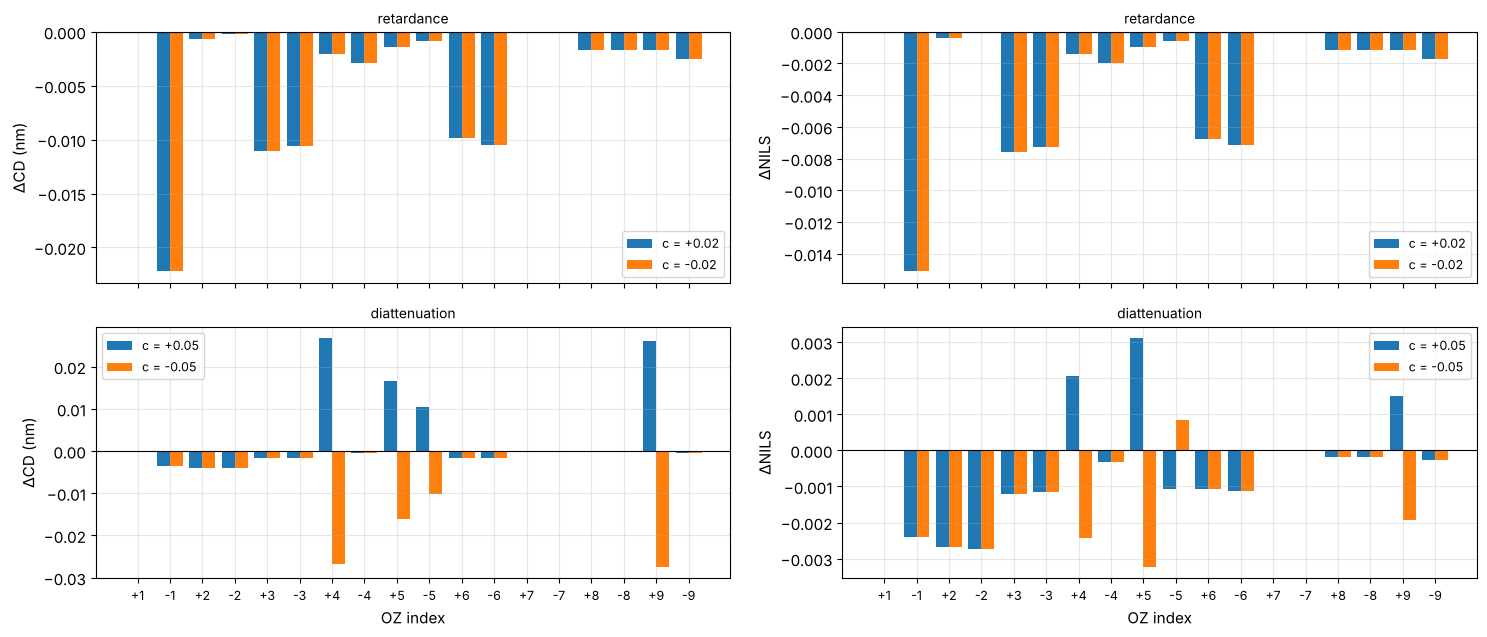

In [13]:
immersion = Projector(1.35, 193.0, n=1.437)
sim = LithoSimulation(MaskLayout.lines_spaces(90.0, 45.0), ThinMask.binary(),
                      Illumination.dipole(0.9, 0.6, n_samples=15, polarization="y"), immersion)
cd0, nils0 = sim.cd(0.3), sim.nils(0.3)
print("without Jones pupil: CD {:.2f} nm, NILS {:.3f}".format(cd0, nils0))

def response(kind, oz, value):
    s = sim.with_(projector=immersion.with_(jones_pupil=jp.PhysicalJonesPupil(**{kind: {oz: value}})))
    return s.cd(0.3) - cd0, s.nils(0.3) - nils0

terms = jp.oz_indices(9)
deltas = {"retardance": 0.02, "diattenuation": 0.05}
results = {(kind, sign): np.array([response(kind, oz, sign*delta) for oz in terms])
           for kind, delta in deltas.items() for sign in (1, -1)}

fig, axes = plt.subplots(2, 2, figsize=(15, 6.5), sharex=True)
x = np.arange(len(terms))
for row, (kind, delta) in zip(axes, deltas.items()):
    for col, metric in enumerate((r"$\Delta$CD (nm)", r"$\Delta$NILS")):
        ax = row[col]
        for sign, offset in ((1, -0.2), (-1, 0.2)):
            ax.bar(x + offset, results[kind, sign][:, col], 0.4, label="c = {:+g}".format(sign*delta))
        ax.axhline(0, color="k", lw=0.8)
        ax.set_ylabel(metric), ax.grid(alpha=0.3)
        ax.set_title(kind, fontsize=10)
        ax.legend(fontsize=9)
for ax in axes[1]:
    ax.set_xticks(x), ax.set_xticklabels(["{:+d}".format(t) for t in terms], fontsize=9)
    ax.set_xlabel("OZ index")
plt.tight_layout()

Two classes of response appear, in line with the sensitivity analysis of
Ruoff and Totzeck:

- **Retardance acts quadratically**: both signs lower the NILS by the same
  amount. The TE light at the poles is an eigenstate of an x/y retarder
  (OZ $+1$ does nothing), but any other orientation converts part of it
  into TM light, which images with less contrast at this NA. OZ $-1$
  (45°) is the most harmful; the other terms matter as far as they rotate
  the axis at the positions of the orders in the pupil.
- **Diattenuation acts linearly** through the terms that change the
  transmission of the zero order relative to the first orders, which lie at
  different positions in the pupil (OZ $+4$, $\pm5$, $+9$ here). A constant
  x/y term (OZ $+1$) only scales the dose, which the normalization to the
  open frame removes.

A tolerance therefore follows from the quadratic coefficient for
retardance and from the linear one for diattenuation. For this two-beam
case the effects are small: even 0.05 waves of the worst retardance term
(OZ $-1$) cost about 0.1 nm of CD and 3 % of the NILS.

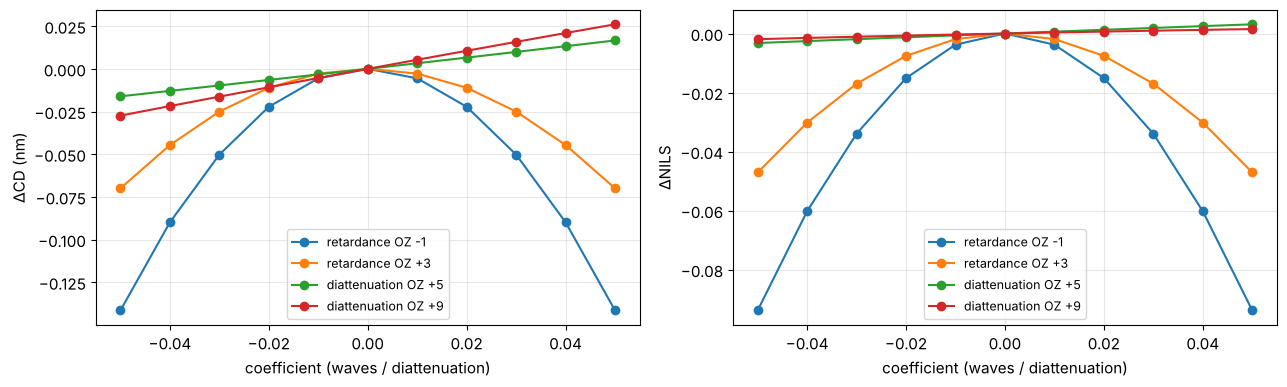

In [14]:
c = np.linspace(-0.05, 0.05, 11)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for kind, oz in (("retardance", -1), ("retardance", 3), ("diattenuation", 5), ("diattenuation", 9)):
    r = np.array([response(kind, oz, v) for v in c])
    for ax, col in zip(axes, r.T):
        ax.plot(c, col, "o-", label="{} OZ {:+d}".format(kind, oz))
for ax, label in zip(axes, (r"$\Delta$CD (nm)", r"$\Delta$NILS")):
    ax.set_xlabel("coefficient (waves / diattenuation)"), ax.set_ylabel(label)
    ax.grid(alpha=0.3), ax.legend(fontsize=9)
plt.tight_layout()

## Summary

- `jones_pupil`: Pauli algebra, orientation Zernike polynomials, the polar
  decomposition and two fitted representations, `PauliZernikePupil` and
  `PhysicalJonesPupil` (OZP retardance and diattenuation). Both plug into
  `Projector(jones_pupil=...)` for Abbe and Hopkins imaging, and they can be
  chained with `@`.
- `lens.lens_jones_pupil()`: polarization ray trace of a lens with Fresnel
  coefficients, optional coatings (`quarter_wave_coating()` or any thin
  film stack per surface) and birefringent elements (`CubicCrystal`, the
  intrinsic birefringence of CaF$_2$ with any axis and clocking).
- The ray traced lens is a published ArF water immersion design (NA 1.35);
  section 6 uses OZP terms chosen by hand on a generic ArFi projector.
- The uncoated lens is a strong radial diattenuator (OZ $+5$); a
  coating trades diattenuation for retardance and adds a scalar wavefront.
- Retardance comes from coatings at large angles, CaF$_2$ elements and
  stress. CaF$_2$ elements bring threefold ([111]) or fourfold ([100])
  patterns that clocking largely compensates; uncompensated, they cost NILS
  with polarized illumination and cause an H–V bias at NA 1.35.
- OZPs sort polarization errors by symmetry like Zernikes sort wavefronts;
  CD responds quadratically to retardance and linearly to diattenuation.
- Not included: a ray traced stress birefringence (modelled here by OZP
  terms), and polarization effects of the
  mask and resist interfaces beyond those already in `FilmMask`,
  `RigorousMask` and `WaferStack`.